# V8 checkpoint inference vs. heuristic and optimal baselines

Run the **four code cells in order**. Place this notebook in `COST_AND_INFERENCE_TIME_COMPARISON` beside the `<N> CN` folders and `rebootal_solutions`. Cell 1 discovers folders and defines the **V8 actor architecture**; Cell 2 runs each CN folder’s **own** `data_extract_*_updated.py` `process_topology` on every latency JSON, loads **only the exact same-CN V8 checkpoint**, performs the two masked placement stages and writes `v8_ha2c_per_latency.csv`; Cell 3 independently reads baseline JSONs and writes `baseline_per_latency.csv`; Cell 4 reloads both files, aligns **exact `(CNs, latency_index)` pairs**, saves the matching audit / mean ± sample SD, and makes **three plots**.

**Interpretation:** `Proposed` is deterministic *masked argmax evaluation* of the trained V8 actors (training used stochastic sampling). Both agent inference times cover the measured placement stage (forward passes, masking, action selection, environment transitions and cost accounting); the separately recorded preprocessing time excludes loading the model/JSON and baseline solver time. The baseline `Time` field may measure a different scope; interpret comparisons accordingly. The V8 source verifies latency feasibility but does not itself implement CPU/memory/storage checks—do not interpret the notebook as measuring those constraints. Missing/mismatched data result in explicit errors or audit entries rather than fabricated measurements.

**Important:** Only the V8 and prior comparison notebooks were provided, not the real latency files, checkpoints, or baseline JSON samples. If a baseline active-node count uses a different key, the extraction cell tells you the available keys; set the explicit schema override rather than guessing.

## Cell 1 — discover input folders and define V8 inference helpers

In [ ]:
from pathlib import Path
import os, re, json, time, importlib.util, math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.distributions import Categorical
from matplotlib.ticker import LogLocator, LogFormatterMathtext, NullFormatter
from IPython.display import display

PROJECT_ROOT = Path(os.environ.get("HA2C_COMPARISON_ROOT", Path.cwd())).expanduser().resolve()
OUTPUT_DIR = PROJECT_ROOT / "v8_comparison_results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
HA2C_CSV = OUTPUT_DIR / "v8_ha2c_per_latency.csv"
BASELINE_CSV = OUTPUT_DIR / "baseline_per_latency.csv"
MATCHED_CSV = OUTPUT_DIR / "three_way_matched_per_latency.csv"
SUMMARY_CSV = OUTPUT_DIR / "comparison_mean_sd_by_CN.csv"
AUDIT_CSV = OUTPUT_DIR / "unmatched_latency_indices.csv"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
LATENCY_LIMIT_MS = 10.0
LARGE_VALUE = 20.0
MAX_PLACEMENT_STEPS = 200   # V8 training uses 200 steps; stop if infeasible/incomplete.
SAVE_FORMATS = ("png", "pdf")
# If your baseline JSON uses different *actual* field names, supply them here.
# E.g., BASELINE_NODE_FIELD_OVERRIDES = {"Heuristic": "actual_key", "Optimal": "actual_key"}
BASELINE_NODE_FIELD_OVERRIDES = {}
BASELINE_ROOT_OVERRIDE = None  # Set to full path if automatic discovery is ambiguous.

plt.rcParams.update({
    "font.family": "DejaVu Serif", "font.size": 12, "axes.labelsize": 19,
    "xtick.labelsize": 16, "ytick.labelsize": 16, "legend.fontsize": 16,
    "axes.linewidth": 1.6, "lines.linewidth": 3.2,
    "grid.linewidth": 0.8, "savefig.dpi": 600, "pdf.fonttype": 42,
    "ps.fonttype": 42,
})
COLORS = {"Proposed": "#2359c4", "Heuristic": "#e66b16", "Optimal": "#218838"}
MARKERS = {"Proposed": "^", "Heuristic": "s", "Optimal": "o"}
METHODS = ("Proposed", "Heuristic", "Optimal")

CN_PATTERN = re.compile(r"^(\d+)[ _-]*CNs?$", re.I)
def discover_cn_folders():
    out = {}
    for p in PROJECT_ROOT.iterdir():
        if not p.is_dir():
            continue
        match = CN_PATTERN.fullmatch(p.name)
        if match:
            cn = int(match.group(1))
            if cn in out:
                raise ValueError(f"Duplicate folder for {cn} CN: {out[cn]} and {p}")
            if not (p / "latency_files").is_dir():
                raise FileNotFoundError(f"Missing latency_files directory: {p}")
            out[cn] = p
    if not out:
        raise FileNotFoundError(f"No '<number> CN' folder with latency_files under {PROJECT_ROOT}")
    return dict(sorted(out.items()))

CN_FOLDERS = discover_cn_folders()
print("Detected CN folders:", {n: str(p) for n, p in CN_FOLDERS.items()})

# This is the V8 Actor architecture. Its original fc1 refers to the current
# global state.shape[0]; here n_nodes is passed explicitly (same dimensions).
class V8Actor(nn.Module):
    def __init__(self, n_nodes):
        super().__init__()
        if n_nodes < 8:
            raise ValueError("V8's three 2x2 pooling layers require at least 8 nodes")
        self.action_size = n_nodes
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, stride=1, padding=1)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.fc1 = nn.Linear(64 * (n_nodes // 8) * (n_nodes // 8), 1024)
        self.fc2 = nn.Linear(1024, 512)
        self.fc4 = nn.Linear(512, n_nodes)

    def forward(self, x):
        x = x.unsqueeze(1)
        x = self.pool1(F.relu(self.conv1(x)))
        x = self.pool2(F.relu(self.conv2(x)))
        x = self.pool3(F.relu(self.conv3(x)))
        x = x.reshape(x.size(0), -1)
        logits = self.fc4(F.relu(self.fc2(F.relu(self.fc1(x)))))
        return Categorical(logits=logits)  # identical to V8 actor return type


def select_checkpoint(cn, folder):
    # Do not silently substitute another CN's model or a similarly named checkpoint.
    candidates = sorted(p for p in folder.glob("*.pt") if "trained_models" in p.name.lower())
    tagged = [p for p in candidates if re.search(rf"(?<!\d){cn}(?!\d)", p.stem)]
    if len(tagged) != 1:
        raise FileNotFoundError(
            f"Expected exactly ONE same-CN 'trained_models' .pt for {cn} CN in {folder}; "
            f"found {tagged}. Other candidates: {candidates}. Refusing any checkpoint substitution."
        )
    return tagged[0]


def load_v8_actors(cn, checkpoint_path):
    # Only load checkpoints from your trusted local training run.
    try:
        ckpt = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    except TypeError as exc:
        raise RuntimeError("Use a PyTorch version supporting torch.load(weights_only=True)") from exc
    if not isinstance(ckpt, dict):
        raise TypeError(f"{checkpoint_path}: expected V8 checkpoint dict, got {type(ckpt)}")
    needed = ("actor1_state_dict", "actor2_state_dict")
    if any(k not in ckpt for k in needed):
        raise KeyError(f"{checkpoint_path}: missing V8 actor keys {needed}; found {list(ckpt)}")
    for k in needed:
        weights = ckpt[k]
        if "fc4.weight" not in weights or "fc1.weight" not in weights:
            raise KeyError(f"{checkpoint_path} {k}: missing expected V8 network weights")
        out_n = int(weights["fc4.weight"].shape[0])
        expected_fc1 = 64 * (cn // 8) ** 2
        if out_n != cn or int(weights["fc1.weight"].shape[1]) != expected_fc1:
            raise ValueError(
                f"CHECKPOINT MISMATCH: {checkpoint_path} {k} has action_size={out_n}, "
                f"fc1_input={weights['fc1.weight'].shape[1]}; {cn} CN expects "
                f"action_size={cn}, fc1_input={expected_fc1}. No other checkpoint will be used."
            )
    actor1, actor2 = V8Actor(cn), V8Actor(cn)
    actor1.load_state_dict(ckpt["actor1_state_dict"], strict=True)
    actor2.load_state_dict(ckpt["actor2_state_dict"], strict=True)
    actor1.to(DEVICE).eval()
    actor2.to(DEVICE).eval()
    return actor1, actor2


def select_extractor(folder, cn):
    # Use the *same* extraction routine as V8 rather than inventing a JSON parser.
    preferred = folder / f"data_extract_{cn}_updated.py"
    if preferred.is_file():
        return preferred
    candidates = sorted(folder.glob("data_extract*updated.py"))
    if len(candidates) != 1:
        raise FileNotFoundError(
            f"No unambiguous V8 process_topology extractor in {folder}: {candidates}. "
            "Set the extractor filename explicitly before running."
        )
    return candidates[0]


def load_extractor(extractor_path, cn):
    spec = importlib.util.spec_from_file_location(f"v8_topology_extractor_{cn}", extractor_path)
    if spec is None or spec.loader is None:
        raise ImportError(f"Cannot import {extractor_path}")
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    if not callable(getattr(module, "process_topology", None)):
        raise AttributeError(f"{extractor_path} lacks callable process_topology(path)")
    return module.process_topology


def latency_index(path, cn):
    # Accept earlier notebook conventions and other files ending in _<index>.json.
    m = re.fullmatch(rf"{cn}[_\s-]*CNs?[_\s-]*(?:timestamp|topology)[_\s-]*(\d+)\.json", path.name, re.I)
    if m is None:
        m = re.search(r"[_-](\d+)\.json$", path.name, re.I)
    if m is None:
        raise ValueError(f"Cannot determine latency index from {path.name}; rename with '_<index>.json'")
    return int(m.group(1))


def latency_files_for_cn(folder, cn):
    found = {}
    for p in sorted((folder / "latency_files").rglob("*.json")):
        idx = latency_index(p, cn)
        if idx in found:
            raise ValueError(f"Duplicate latency index {idx} for {cn} CN: {found[idx]} and {p}")
        found[idx] = p
    if not found:
        raise FileNotFoundError(f"No latency JSONs under {folder / 'latency_files'}")
    return dict(sorted(found.items()))


def validate_topology(process_topology, path, cn):
    result = process_topology(str(path))
    if len(result) != 4:
        raise ValueError(f"{path}: V8 process_topology must return (cloud, regional, edge, latency)")
    cloud, regional, edge, latency = result
    latency = np.asarray(latency, dtype=np.float64)
    if latency.shape != (cn, cn) or not np.isfinite(latency).all():
        raise ValueError(f"{path}: latency must be finite ({cn}, {cn}), got {latency.shape}")
    kinds = {}
    for cls, ids in enumerate((cloud, regional, edge)):
        for node in ids:
            k = int(node)
            if k < 0 or k >= cn or k in kinds:
                raise ValueError(f"{path}: duplicate/out-of-range node ID: {k}")
            kinds[k] = cls
    if len(kinds) != cn:
        raise ValueError(f"{path}: node-class lists cover {len(kinds)} of {cn} nodes")
    edge = np.asarray(edge, dtype=int)
    if edge.size == 0:
        raise ValueError(f"{path}: V8 Agent 1 has no E2N targets")
    return latency, edge, kinds


def tick_sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


def masked_argmax(actor, state_np, target_nodes):
    valid = np.any(state_np[:, target_nodes] <= LATENCY_LIMIT_MS, axis=1)
    if not valid.any():
        raise RuntimeError("No valid action remains while target nodes are still uncovered")
    inp = torch.as_tensor(state_np, dtype=torch.float32, device=DEVICE).unsqueeze(0)
    dist = actor(inp)
    logits = dist.logits.squeeze(0)
    if not torch.isfinite(logits).all():
        raise FloatingPointError("Actor emitted nonfinite logits")
    mask = torch.as_tensor(valid, dtype=torch.bool, device=DEVICE)
    # V8 logit-space masking; argmax is deterministic evaluation, not training sampling.
    masked_logits = logits.masked_fill(~mask, torch.finfo(logits.dtype).min)
    return int(torch.argmax(masked_logits).item())


def v8_update_state(state, action):
    # Exact V8 update_state(state, action), with the training sentinel/limit.
    updated = state.copy()
    latency_idx = np.where(updated[action, :] <= LATENCY_LIMIT_MS)[0]
    updated[:, latency_idx] = LARGE_VALUE
    return updated

FIXED_COSTS = np.array([5., 10., 20.])
VARIABLE_COSTS1 = np.array([[4., 8., 16.], [1., 2., 4.]])  # xApp, E2T
VARIABLE_COSTS2 = np.array([[2., 4., 8.], [2., 4., 8.]])   # SDL, DB

def v8_action_cost(action, previously_activated_nodes, node_classes, variable_costs):
    # V8 compute_cost_new: fixed cost waived for a previously activated *node*,
    # while component processing cost is counted for each newly placed service pair.
    cls = node_classes[int(action)]
    fixed = 0. if int(action) in previously_activated_nodes else FIXED_COSTS[cls]
    return float(fixed + variable_costs[:, cls].sum())


def run_v8_inference(latency, edge_nodes, kinds, actor1, actor2):
    state = latency.copy()
    state1 = state.copy()
    non_e2 = np.ones(state.shape[1], dtype=bool)
    non_e2[edge_nodes] = False
    state1[:, non_e2] = LARGE_VALUE  # exactly V8 cell 16
    selected1, selected2 = [], []
    cost1, cost2 = 0., 0.

    # Count each stage including logits, valid masking, action, transition, and cost.
    # Exclude topology-file parsing and model loading; separately record association time.
    tick_sync()
    t1 = time.perf_counter()
    with torch.inference_mode():
        for _ in range(MAX_PLACEMENT_STEPS):
            if np.all(state1[:, edge_nodes] == LARGE_VALUE):
                break
            a = masked_argmax(actor1, state1, edge_nodes)
            cost1 += v8_action_cost(a, selected1, kinds, VARIABLE_COSTS1)
            selected1.append(a)
            state1 = v8_update_state(state1, a)
        if not np.all(state1[:, edge_nodes] == LARGE_VALUE):
            raise RuntimeError("Agent 1 exceeded V8 step budget with uncovered E2Ns")
    tick_sync()
    agent1_time_s = time.perf_counter() - t1

    # V8 cell 21: associate every E2 node to the selected G1 with least latency;
    # build stage-2 state from each G1's *worst* assigned first-stage latency.
    assoc_start = time.perf_counter()
    unique1 = sorted(set(selected1))
    if not unique1:
        raise RuntimeError("Agent 1 selected no nodes")
    e2_to_g1 = {int(e): min(unique1, key=lambda g: latency[int(g), int(e)]) for e in edge_nodes}
    g1_to_e2 = {}
    for e, g1 in e2_to_g1.items():
        if latency[g1, e] > LATENCY_LIMIT_MS:
            raise RuntimeError(f"E2 {e} has no <=10 ms selected G1")
        g1_to_e2.setdefault(g1, []).append(e)
    active_g1 = np.asarray(sorted(g1_to_e2), dtype=int)
    worst_first = {g: max(float(latency[g, e]) for e in es) for g, es in g1_to_e2.items()}
    state2 = np.full_like(latency, LARGE_VALUE, dtype=float)
    for g in active_g1:
        state2[:, g] = latency[:, g] + worst_first[int(g)]
    if any(not np.any(state2[:, g] <= LATENCY_LIMIT_MS) for g in active_g1):
        raise RuntimeError("V8 stage 2 has an infeasible active G1")
    association_time_s = time.perf_counter() - assoc_start

    tick_sync()
    t2 = time.perf_counter()
    with torch.inference_mode():
        for _ in range(MAX_PLACEMENT_STEPS):
            if np.all(state2[:, active_g1] == LARGE_VALUE):
                break
            a = masked_argmax(actor2, state2, active_g1)
            cost2 += v8_action_cost(a, selected1 + selected2, kinds, VARIABLE_COSTS2)
            selected2.append(a)
            state2 = v8_update_state(state2, a)
        if not np.all(state2[:, active_g1] == LARGE_VALUE):
            raise RuntimeError("Agent 2 exceeded V8 step budget with uncovered G1s")
    tick_sync()
    agent2_time_s = time.perf_counter() - t2

    # V8 cell 24 validates *each* complete loop with the chosen G1/G2 associations.
    unique2 = sorted(set(selected2))
    g1_to_g2 = {}
    for g1 in active_g1:
        options = [g2 for g2 in unique2
                   if worst_first[int(g1)] + float(latency[g2, g1]) <= LATENCY_LIMIT_MS]
        if not options:
            raise RuntimeError(f"No selected G2 satisfies full-loop latency for G1={g1}")
        g1_to_g2[int(g1)] = min(options,
                                key=lambda g2: worst_first[int(g1)] + float(latency[g2, g1]))
    worst_loop = max(float(latency[e2_to_g1[int(e)], int(e)])
                     + float(latency[g1_to_g2[e2_to_g1[int(e)]], e2_to_g1[int(e)]])
                     for e in edge_nodes)
    if worst_loop > LATENCY_LIMIT_MS:
        raise RuntimeError(f"Complete-loop latency violation: {worst_loop:.6f} ms")
    return dict(agent1_selected_nodes=json.dumps(selected1),
                agent2_selected_nodes=json.dumps(selected2),
                agent1_active_nodes=len(unique1), agent2_active_nodes=len(unique2),
                unique_active_nodes=len(set(selected1) | set(selected2)),
                agent1_cost=cost1, agent2_cost=cost2, total_cost=cost1 + cost2,
                agent1_inference_time_s=agent1_time_s,
                agent2_inference_time_s=agent2_time_s,
                association_time_s=association_time_s,
                total_inference_time_s=agent1_time_s + association_time_s + agent2_time_s,
                max_complete_loop_latency_ms=worst_loop,
                e2_to_g1=json.dumps(e2_to_g1), g1_to_g2=json.dumps(g1_to_g2))

print("Device:", DEVICE, "| Output:", OUTPUT_DIR)

## Cell 2 — run each latency JSON through the exact same-CN V8 checkpoint; write Proposed CSV

In [ ]:
rows, failed = [], []
for cn, folder in CN_FOLDERS.items():
    checkpoint = select_checkpoint(cn, folder)
    extractor_file = select_extractor(folder, cn)
    process_topology = load_extractor(extractor_file, cn)
    actors = load_v8_actors(cn, checkpoint)  # strict shape + state_dict validation
    latency_files = latency_files_for_cn(folder, cn)
    print(f"\n{cn} CN: checkpoint={checkpoint.name}, extractor={extractor_file.name}, "
          f"latency files={len(latency_files)}")
    for index, path in latency_files.items():
        try:
            latency, e2_nodes, classes = validate_topology(process_topology, path, cn)
            observation = run_v8_inference(latency, e2_nodes, classes, *actors)
            rows.append(dict(CNs=cn, latency_index=index, latency_file=path.name,
                             checkpoint_file=checkpoint.name, **observation))
        except Exception as exc:
            failed.append(dict(CNs=cn, latency_index=index, latency_file=path.name,
                               error=f"{type(exc).__name__}: {exc}"))
            print(f"FAILED {cn} CN, index {index}, {path.name}: {exc}")
    del actors
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

failure_path = OUTPUT_DIR / "v8_inference_failures.csv"
pd.DataFrame(failed, columns=["CNs", "latency_index", "latency_file", "error"]).to_csv(failure_path, index=False)
if not rows:
    raise RuntimeError(f"No successful V8 inference observations. Inspect {failure_path}")
proposed_df = pd.DataFrame(rows).sort_values(["CNs", "latency_index"]).reset_index(drop=True)
if proposed_df.duplicated(["CNs", "latency_index"]).any():
    raise ValueError("Duplicate Proposed (CN, latency_index)")
proposed_df.to_csv(HA2C_CSV, index=False)
print(f"Saved {len(proposed_df)} V8 inference records: {HA2C_CSV}")
if failed:
    print(f"WARNING: {len(failed)} files failed; details saved in {failure_path}. "
          "Only successful indices can enter the matched comparison.")
display(proposed_df[["CNs", "latency_index", "agent1_cost", "agent2_cost",
                     "total_cost", "agent1_active_nodes", "agent2_active_nodes",
                     "unique_active_nodes", "agent1_inference_time_s",
                     "agent2_inference_time_s", "total_inference_time_s"]].head(12))

## Cell 3 — independent baseline JSON extraction; write baseline CSV

The original comparison notebook uses baseline `Total_Cost` and `Time` (seconds). For an active-node count, this cell accepts an **explicit count key** or a clearly labeled **list of active/selected node IDs**; it stops and prints the JSON keys if neither exists. For nonstandard keys set `BASELINE_NODE_FIELD_OVERRIDES` in Cell 1. A baseline JSON whose `Time` is absent or nonpositive is not assigned an invented inference time.

In [ ]:
import json

sample_path = (
    BASELINE_ROOT
    / "heuristic"
    / "45_CNs_timestamp_0.json"
)

with open(sample_path, "r") as f:
    data = json.load(f)

print("active_CNs type:", type(data["active_CNs"]))
print("active_CNs value:", data["active_CNs"])

In [ ]:
def find_baseline_root():
    if BASELINE_ROOT_OVERRIDE is not None:
        root = Path(BASELINE_ROOT_OVERRIDE).expanduser().resolve()
        if not root.is_dir():
            raise FileNotFoundError(root)
        return root
    candidates = [p for p in PROJECT_ROOT.iterdir() if p.is_dir() and
                  p.name.lower().replace("_", "").replace(" ", "") in
                  {"rebootalsolutions", "rebuttalsolutions", "rebutalsolutions"}]
    if len(candidates) != 1:
        raise FileNotFoundError(f"Expected one rebootal_solutions root, found {candidates}; "
                                "set BASELINE_ROOT_OVERRIDE")
    return candidates[0]

BASELINE_ROOT = find_baseline_root()
# Expand BASELINE_DIR_NAMES only when a new *actual* baseline method has been added.
BASELINE_DIR_NAMES = {"Heuristic": ("heuristic", "huristic"),
                      "Optimal": ("optimal", "optimum")}

def baseline_method_folder(method):
    matches = [p for p in BASELINE_ROOT.iterdir() if p.is_dir()
               and p.name.lower() in BASELINE_DIR_NAMES[method]]
    if len(matches) != 1:
        raise FileNotFoundError(f"Expected exactly one {method} folder in {BASELINE_ROOT}: {matches}")
    return matches[0]

def extract_active_count(data, method, path):

    # --------------------------------------------------------
    # Possible fields containing an integer active-node count
    # --------------------------------------------------------

    standard_counts = (
        "Total_Active_Nodes",
        "total_active_nodes",
        "Number_of_Active_Nodes",
        "number_of_active_nodes",
        "Num_Active_Nodes",
        "num_active_nodes",
        "Unique_Active_Nodes",
        "unique_active_nodes",
        "active_nodes_count",
        "num_unique_active_nodes",
        "number_of_unique_active_nodes",
    )

    # --------------------------------------------------------
    # Possible fields containing a list of active node IDs
    # --------------------------------------------------------

    standard_lists = (
        "Active_Nodes",
        "active_nodes",
        "active_CNs",       # Added: your baseline JSON field
        "Active_CNs",
        "selected_CNs",
        "Selected_CNs",
        "Selected_Nodes",
        "selected_nodes",
        "Activated_Nodes",
        "activated_nodes",
        "Unique_Nodes",
        "unique_nodes",
    )

    # --------------------------------------------------------
    # Identify the active-node field
    # --------------------------------------------------------

    key = BASELINE_NODE_FIELD_OVERRIDES.get(method)

    if key is None:

        key = next(
            (
                k for k in standard_counts + standard_lists
                if k in data
            ),
            None
        )

    if key is None:

        raise KeyError(
            f"{path}: unknown active-node schema. "
            f"JSON keys: {sorted(data)}"
        )

    value = data[key]

    # --------------------------------------------------------
    # Case 1: Integer active-node count
    # --------------------------------------------------------

    if isinstance(value, bool):

        raise TypeError(
            f"{path}: {key} cannot be a boolean."
        )

    if isinstance(value, (int, float)):

        if not np.isfinite(value):

            raise ValueError(
                f"{path}: {key} contains a nonfinite value."
            )

        if float(value).is_integer() and value >= 0:

            return int(value)

        raise ValueError(
            f"{path}: invalid active-node count: {value}"
        )

    # --------------------------------------------------------
    # Case 2: List of active computing-node IDs
    # --------------------------------------------------------

    if isinstance(value, list):

        if not all(
            isinstance(node, (int, str))
            and not isinstance(node, bool)
            for node in value
        ):

            raise TypeError(
                f"{path}: {key} contains non-scalar node IDs. "
                "Inspect the JSON structure before counting."
            )

        return len(set(map(str, value)))

    # --------------------------------------------------------
    # Case 3: Unsupported format
    # --------------------------------------------------------

    raise TypeError(
        f"{path}: Cannot interpret {key} "
        f"of type {type(value).__name__} "
        "as an active-node count."
    )

baseline_rows = []
for method in BASELINE_DIR_NAMES:
    base_dir = baseline_method_folder(method)
    print(f"{method}: {base_dir}")
    for cn in CN_FOLDERS:
        found = {}
        for path in sorted(base_dir.rglob("*.json")):
            # Require the actual CN prefix; never mix data from other node sizes.
            pat = rf"{cn}[_\s-]*CNs?[_\s-]*(?:timestamp|topology)[_\s-]*(\d+)\.json"
            m = re.fullmatch(pat, path.name, re.I)
            if not m:
                continue
            idx = int(m.group(1))
            if idx in found:
                raise ValueError(f"Duplicate {method} {cn} CN index {idx}: {found[idx]} and {path}")
            found[idx] = path
        if not found:
            print(f"WARNING: no {method} files for {cn} CN under {base_dir}")
        for idx, path in sorted(found.items()):
            with path.open("r", encoding="utf-8") as f:
                data = json.load(f)
            if not isinstance(data, dict) or "Total_Cost" not in data:
                raise KeyError(f"{path}: missing original-baseline 'Total_Cost'; keys={list(data) if isinstance(data, dict) else type(data)}")
            time_key = next((k for k in ("Time", "time", "execution_time", "Execution_Time",
                                        "execution_time_s", "inference_time_s") if k in data), None)
            if time_key is None:
                raise KeyError(f"{path}: no measured baseline time. Keys={list(data)}")
            c, t = float(data["Total_Cost"]), float(data[time_key])
            if not np.isfinite(c) or c < 0 or not np.isfinite(t) or t <= 0:
                raise ValueError(f"{path}: invalid cost/time: {c}/{t}")
            nodes = extract_active_count(data, method, path)
            baseline_rows.append(dict(CNs=cn, latency_index=idx, approach=method,
                                      json_file=str(path.relative_to(PROJECT_ROOT)),
                                      total_cost=c, unique_active_nodes=nodes,
                                      total_inference_time_s=t, time_field=time_key))
if not baseline_rows:
    raise RuntimeError("No baseline records found; check baseline JSON naming conventions")
baseline_df = pd.DataFrame(baseline_rows).sort_values(["CNs", "latency_index", "approach"])
if baseline_df.duplicated(["CNs", "latency_index", "approach"]).any():
    raise ValueError("Duplicate baseline CN/index/approach")
baseline_df.to_csv(BASELINE_CSV, index=False)
print(f"Saved {len(baseline_df)} baseline observations: {BASELINE_CSV}")
display(baseline_df.head(12))

## Cell 4 — reload both CSVs, match identical latency indices, summarize mean ± SD, plot three figures

**No zero-filled observations.** An index missing from any approach is excluded from **all** approaches for that CN and listed in the audit. Sample standard deviation is computed with `ddof=1` (shown as 0 for a single matched observation). Log-scale lower error bars are clipped **only for display**, never in the saved statistics.

In [ ]:
proposed = pd.read_csv(HA2C_CSV)
baselines = pd.read_csv(BASELINE_CSV)
KEY = ["CNs", "latency_index"]
NEEDED = ("total_cost", "unique_active_nodes", "total_inference_time_s")
for name, df in (("Proposed", proposed), ("Baseline", baselines)):
    if not set(KEY + list(NEEDED)).issubset(df.columns):
        raise KeyError(f"{name} CSV is missing required columns: {set(KEY + list(NEEDED)) - set(df.columns)}")
proposed["approach"] = "Proposed"
all_df = pd.concat([proposed[KEY + ["approach"] + list(NEEDED)],
                    baselines[KEY + ["approach"] + list(NEEDED)]], ignore_index=True)
if all_df.duplicated(KEY + ["approach"]).any():
    raise ValueError("Duplicate (CN, latency index, approach) in saved files")
for metric in NEEDED:
    all_df[metric] = pd.to_numeric(all_df[metric], errors="raise")
    if not np.isfinite(all_df[metric].to_numpy(dtype=float)).all():
        raise ValueError(f"Nonfinite {metric} in saved CSVs")
if (all_df["total_inference_time_s"] <= 0).any():
    raise ValueError("Inference times must be strictly positive for log plot")
if (all_df[["total_cost", "unique_active_nodes"]] < 0).any().any():
    raise ValueError("Negative cost or node count")

all_cn = sorted(set(proposed.CNs.astype(int)) | set(baselines.CNs.astype(int)))
audit, matched_records = [], []
for cn in all_cn:
    subset = all_df[all_df.CNs == cn]
    per_method = {m: set(subset.loc[subset.approach == m, "latency_index"].astype(int))
                  for m in METHODS}
    common = set.intersection(*(per_method[m] for m in METHODS))
    for idx in sorted(set.union(*(per_method[m] for m in METHODS))):
        if idx not in common:
            audit.append(dict(CNs=cn, latency_index=idx,
                              **{f"has_{m.lower()}": idx in per_method[m] for m in METHODS}))
    for idx in sorted(common):
        matched_records.extend(subset.loc[subset.latency_index == idx].to_dict("records"))
    print(f"{cn} CN: matched {len(common)} | " + " | ".join(f"{m}={len(per_method[m])}" for m in METHODS))

pd.DataFrame(audit, columns=["CNs", "latency_index"] +
             [f"has_{m.lower()}" for m in METHODS]).to_csv(AUDIT_CSV, index=False)
if not matched_records:
    raise RuntimeError(f"No exact three-way matches. Check {AUDIT_CSV} and the separate input CSVs")
matched = pd.DataFrame(matched_records).sort_values(KEY + ["approach"]).reset_index(drop=True)
matched.to_csv(MATCHED_CSV, index=False)
print("Matched observations:", len(matched), "| Unmatched indices:", len(audit))

summary = (matched.groupby(["CNs", "approach"])
           .agg(n=("total_cost", "size"),
                cost_mean=("total_cost", "mean"), cost_sd=("total_cost", "std"),
                nodes_mean=("unique_active_nodes", "mean"), nodes_sd=("unique_active_nodes", "std"),
                time_mean_s=("total_inference_time_s", "mean"),
                time_sd_s=("total_inference_time_s", "std"))
           .reset_index().sort_values(["CNs", "approach"]))
for col in ("cost_sd", "nodes_sd", "time_sd_s"):
    summary[col] = summary[col].fillna(0.0)
summary.to_csv(SUMMARY_CSV, index=False)
display(summary)

# # Only plot CN configurations with a complete matched comparison.
# valid_cn = sorted(summary.CNs.unique().astype(int).tolist())
# x = np.arange(len(valid_cn))
# width = 0.26

# def stats_for(method, column):
#     s = summary[summary.approach == method].set_index("CNs").reindex(valid_cn)
#     if s[column].isna().any():
#         raise RuntimeError(f"Missing matched summary for {method} {column}")
#     return s[column].to_numpy(dtype=float)

# def common_style(ax):
#     ax.set_xticks(x, labels=[str(n) for n in valid_cn])
#     ax.set_xlabel("No. of Computing Nodes", fontsize=20)
#     ax.tick_params(axis="both", which="major", direction="in",
#                    labelsize=17, width=1.5, length=7)
#     ax.grid(axis="y", linestyle="--", alpha=0.40)
#     ax.set_axisbelow(True)
#     ax.legend(loc="best", fontsize=16, frameon=True, edgecolor="black", fancybox=False)

# def save_show(fig, basename):
#     fig.tight_layout()
#     for ext in SAVE_FORMATS:
#         out = OUTPUT_DIR / f"{basename}.{ext}"
#         fig.savefig(out, dpi=600, bbox_inches="tight")
#         print("Saved:", out)
#     plt.show()
#     plt.close(fig)

# # Figure 1: mean ± SD placement cost (bar plot)
# fig, ax = plt.subplots(figsize=(11, 6.3))
# for shift, method in zip((-1, 0, 1), METHODS):
#     ax.bar(x + shift * width, stats_for(method, "cost_mean"), width,
#            yerr=stats_for(method, "cost_sd"), label=method,
#            color=COLORS[method], edgecolor="black", linewidth=1.1,
#            error_kw=dict(elinewidth=2.0, capsize=6, capthick=2.0), zorder=3)
# common_style(ax)
# ax.set_ylabel("Total Placement Cost", fontsize=20)
# save_show(fig, "total_cost_bar_mean_sd")

# # Figure 2: mean ± SD UNIQUE active node count (bar plot)
# fig, ax = plt.subplots(figsize=(11, 6.3))
# for shift, method in zip((-1, 0, 1), METHODS):
#     ax.bar(x + shift * width, stats_for(method, "nodes_mean"), width,
#            yerr=stats_for(method, "nodes_sd"), label=method,
#            color=COLORS[method], edgecolor="black", linewidth=1.1,
#            error_kw=dict(elinewidth=2.0, capsize=6, capthick=2.0), zorder=3)
# common_style(ax)
# ax.set_ylabel("Number of Active Nodes", fontsize=20)
# save_show(fig, "unique_active_nodes_bar_mean_sd")

# # Figure 3: mean ± SD inference time (log-scale line plot)
# fig, ax = plt.subplots(figsize=(11, 6.3))
# all_lower, all_upper = [], []
# for method in METHODS:
#     mean = stats_for(method, "time_mean_s")
#     sd = stats_for(method, "time_sd_s")
#     if (mean <= 0).any():
#         raise ValueError(f"{method}: cannot plot nonpositive mean on log axis")
#     # Actual SD in SUMMARY_CSV remains unchanged; clip only the drawn lower arm.
#     low = np.minimum(sd, 0.99 * mean)
#     if np.any(low < sd):
#         print(f"Note: {method}: lower time error bar clipped >0 for log-scale display only")
#     all_lower.extend((mean - low).tolist())
#     all_upper.extend((mean + sd).tolist())
#     ax.errorbar(x, mean, yerr=np.vstack((low, sd)), label=method,
#                 color=COLORS[method], linewidth=3.2, linestyle="-",
#                 marker=MARKERS[method], markersize=10, markerfacecolor="white",
#                 markeredgewidth=2.4, elinewidth=2.0, capsize=6, capthick=2.0, zorder=3)
# ax.set_yscale("log")
# ax.yaxis.set_major_locator(LogLocator(base=10))
# ax.yaxis.set_major_formatter(LogFormatterMathtext(base=10))
# ax.yaxis.set_minor_formatter(NullFormatter())
# ax.set_ylim(min(all_lower) * 0.55, max(all_upper) * 1.8)
# common_style(ax)
# ax.grid(axis="y", which="both", linestyle="--", alpha=0.40)
# ax.set_ylabel("Inference Time (s)", fontsize=20)
# save_show(fig, "inference_time_log_line_mean_sd")

# print("Results folder:", OUTPUT_DIR)

Loaded summary CSV:
/home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/v8_comparison_results/comparison_mean_sd_by_CN.csv

Available CN configurations:
[45, 50, 55, 60, 65]

Loaded summary data:


,CNs,approach,n,cost_mean,cost_sd,nodes_mean,nodes_sd,time_mean_s,time_sd_s
0,45,Heuristic,30,816.400000,3.211574e+01,18.000000,0.371391,0.085423,0.003777
1,45,Optimal,30,797.000000,3.326073e+01,17.533333,0.681445,8.340940,1.499698
2,45,Proposed,30,797.000000,4.295547e+01,17.600000,1.373392,0.077669,0.198471
3,50,Heuristic,30,616.200000,3.076205e+01,14.200000,0.761124,0.078556,0.003862
4,50,Optimal,30,548.100000,3.536641e+01,12.200000,0.886683,18.029914,11.511278
5,50,Proposed,30,588.466667,3.031983e+01,13.800000,0.932183,0.032196,0.004831
6,55,Heuristic,29,310.551724,4.374160e+01,9.034483,0.944259,0.072828,0.004572
7,55,Optimal,29,240.310345,4.037954e+01,6.862069,1.025536,16.040515,47.677060
8,55,Proposed,29,309.724138,4.725077e+01,8.962069,0.990099,0.023758,0.002143
9,60,Heuristic,30,77.833333,2.301886e+01,3.066667,0.691492,0.071183,0.004046


Saved: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/v8_comparison_results/total_cost_bar_mean_sd.png
Saved: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/v8_comparison_results/total_cost_bar_mean_sd.pdf


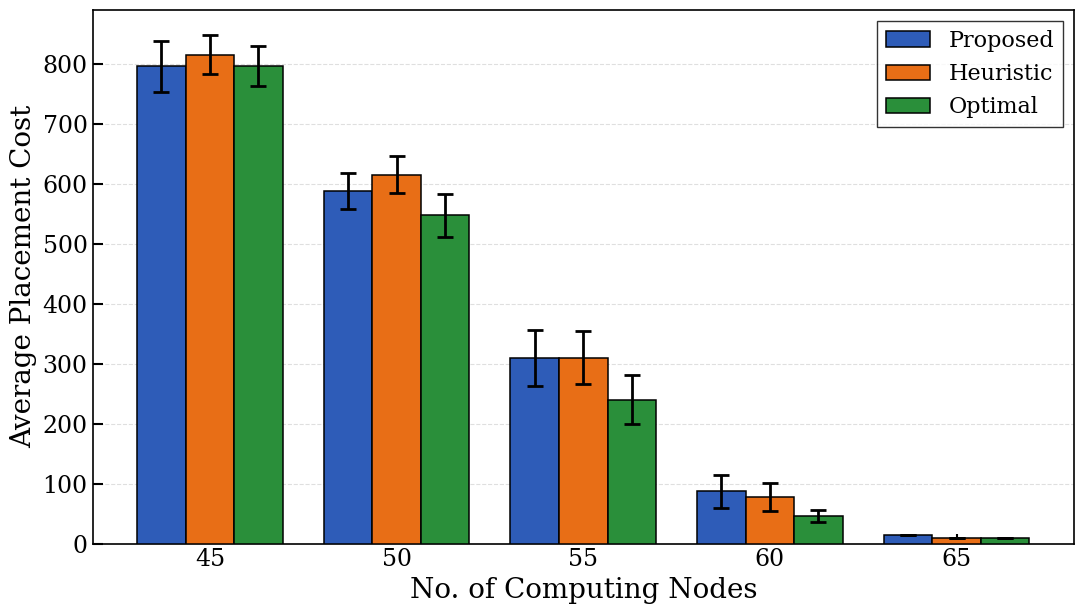

Saved: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/v8_comparison_results/unique_active_nodes_bar_mean_sd.png
Saved: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/v8_comparison_results/unique_active_nodes_bar_mean_sd.pdf


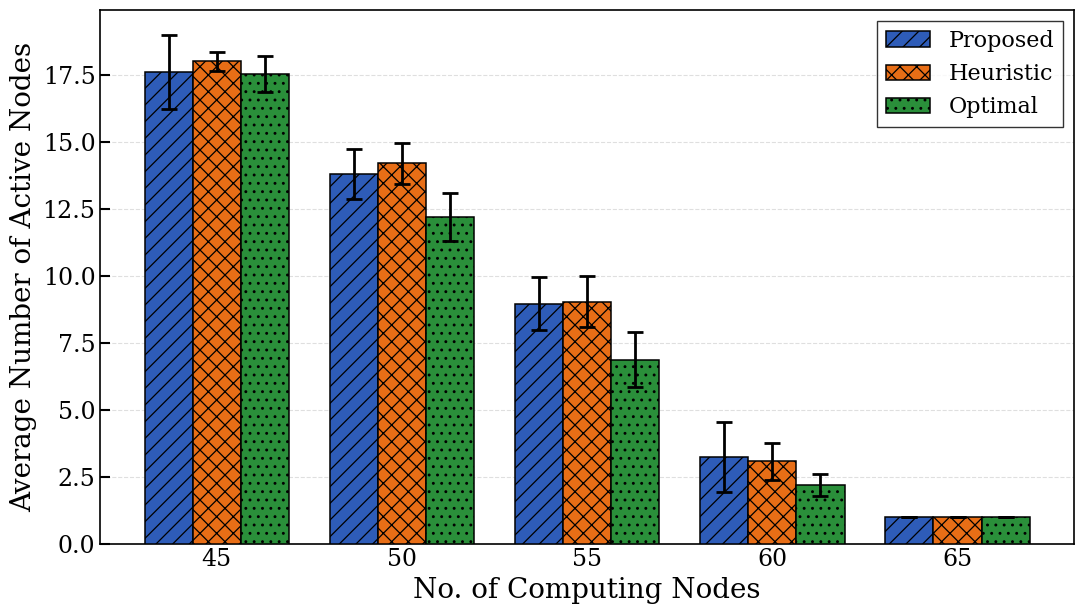

Note: Proposed lower error bars clipped for log-scale display.
Note: Optimal lower error bars clipped for log-scale display.
Saved: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/v8_comparison_results/inference_time_log_line_mean_sd.png
Saved: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/v8_comparison_results/inference_time_log_line_mean_sd.pdf


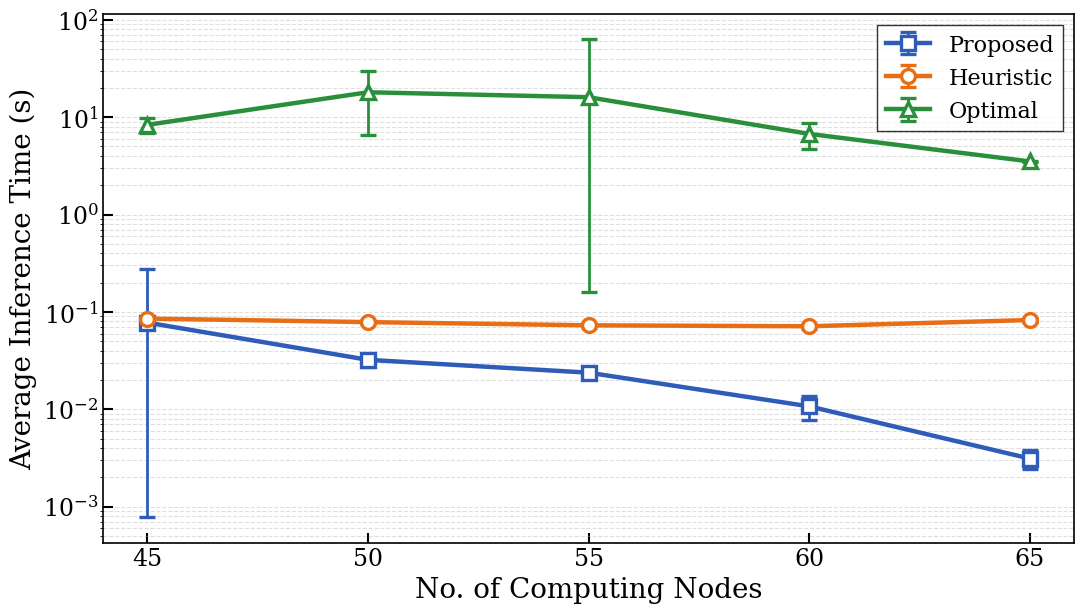


All three figures generated successfully.
Results folder: /home/cci/Downloads/Latest/Revised/cost_and_inference_time_comparison/v8_comparison_results


In [20]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.ticker import (
    LogLocator,
    LogFormatterMathtext,
    NullFormatter
)


# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_ROOT = Path.cwd()

OUTPUT_DIR = PROJECT_ROOT / "v8_comparison_results"

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Read the previously calculated mean and SD
SUMMARY_CSV = (
    OUTPUT_DIR / "comparison_mean_sd_by_CN.csv"
)

# If your CSV is in the current notebook directory,
# change SUMMARY_CSV to:
# SUMMARY_CSV = PROJECT_ROOT / "comparison_mean_sd_by_CN.csv"

SAVE_FORMATS = ("png", "pdf")

METHODS = [
    "Proposed",
    "Heuristic",
    "Optimal"
]

# Original colors
COLORS = {
    "Proposed": "#2E5CB8",
    "Heuristic": "#E86E16",
    "Optimal": "#2A8F3A"
}

# Markers for inference-time plot
MARKERS = {
    "Proposed": "s",
    "Heuristic": "o",
    "Optimal": "^"
}

# Hatches for active-node bar plot
HATCHES = {
    "Proposed": "//",
    "Heuristic": "xx",
    "Optimal": ".."
}


# ============================================================
# 2. LOAD SAVED SUMMARY CSV
# ============================================================

if not SUMMARY_CSV.is_file():

    raise FileNotFoundError(
        f"Summary CSV not found:\n{SUMMARY_CSV}"
    )

summary = pd.read_csv(SUMMARY_CSV)

print("Loaded summary CSV:")
print(SUMMARY_CSV)


# ============================================================
# 3. VALIDATE SAVED SUMMARY DATA
# ============================================================

required_columns = [
    "CNs",
    "approach",
    "n",
    "cost_mean",
    "cost_sd",
    "nodes_mean",
    "nodes_sd",
    "time_mean_s",
    "time_sd_s"
]

missing_columns = (
    set(required_columns) - set(summary.columns)
)

if missing_columns:

    raise KeyError(
        f"Missing columns in summary CSV: "
        f"{sorted(missing_columns)}"
    )


# Convert numeric columns
numeric_columns = [
    col for col in required_columns
    if col != "approach"
]

for col in numeric_columns:

    summary[col] = pd.to_numeric(
        summary[col],
        errors="raise"
    )


# Check for invalid values
if not np.isfinite(
    summary[numeric_columns].to_numpy(dtype=float)
).all():

    raise ValueError(
        "Summary CSV contains NaN or infinite values."
    )


# Check inference times
if (summary["time_mean_s"] <= 0).any():

    raise ValueError(
        "Mean inference times must be positive."
    )


# Check standard deviations
if (
    summary[["cost_sd", "nodes_sd", "time_sd_s"]] < 0
).any().any():

    raise ValueError(
        "Standard deviations must be nonnegative."
    )


# Check duplicate CN/approach combinations
if summary.duplicated(
    ["CNs", "approach"]
).any():

    raise ValueError(
        "Duplicate CN/approach combinations detected."
    )


# ============================================================
# 4. AUTOMATICALLY IDENTIFY CN CONFIGURATIONS
# ============================================================

available_methods = set(summary["approach"])

missing_methods = set(METHODS) - available_methods

if missing_methods:

    raise ValueError(
        f"Missing approaches: {sorted(missing_methods)}"
    )


# Include only CN configurations for which all three
# approaches have summary data.

valid_cn = sorted(
    int(cn)
    for cn in summary["CNs"].unique()
    if set(
        summary.loc[
            summary["CNs"] == cn,
            "approach"
        ]
    ) >= set(METHODS)
)

if not valid_cn:

    raise ValueError(
        "No CN configuration contains all three approaches."
    )


print("\nAvailable CN configurations:")
print(valid_cn)

print("\nLoaded summary data:")

display(
    summary.sort_values(
        ["CNs", "approach"]
    ).reset_index(drop=True)
)


# ============================================================
# 5. IEEE-STYLE PLOT SETTINGS
# ============================================================

plt.rcParams.update({

    "font.family": "DejaVu Serif",

    "font.size": 12,

    "axes.labelsize": 20,

    "xtick.labelsize": 17,

    "ytick.labelsize": 17,

    "legend.fontsize": 16,

    "axes.linewidth": 1.2,

    "lines.linewidth": 2.0,

    "grid.linewidth": 0.8,

    "hatch.linewidth": 0.9,

    "savefig.dpi": 600,

    "pdf.fonttype": 42,

    "ps.fonttype": 42
})


# X-axis positions
x = np.arange(len(valid_cn))

# Bar width
width = 0.26


# ============================================================
# 6. EXTRACT MEAN AND SD DIRECTLY FROM SAVED CSV
# ============================================================

def stats_for(method, column):

    s = (
        summary[summary["approach"] == method]
        .set_index("CNs")
        .reindex(valid_cn)
    )

    if s[column].isna().any():

        raise RuntimeError(
            f"Missing summary data: "
            f"{method}, {column}"
        )

    return s[column].to_numpy(
        dtype=float
    )


# ============================================================
# 7. COMMON PLOTTING STYLE
# ============================================================

def common_style(ax):

    ax.set_xticks(
        x,
        labels=[str(cn) for cn in valid_cn]
    )

    ax.set_xlabel(
        "No. of Computing Nodes",
        fontsize=20
    )

    ax.tick_params(
        axis="both",
        which="major",
        direction="in",
        labelsize=17,
        width=1.5,
        length=7
    )

    ax.grid(
        axis="y",
        linestyle="--",
        linewidth=0.8,
        alpha=0.40
    )

    ax.set_axisbelow(True)

    ax.legend(
        loc="best",
        fontsize=16,
        frameon=True,
        edgecolor="black",
        fancybox=False
    )


# ============================================================
# 8. SAVE AND DISPLAY FUNCTION
# ============================================================

def save_show(fig, basename):

    fig.tight_layout()

    for ext in SAVE_FORMATS:

        output_path = (
            OUTPUT_DIR / f"{basename}.{ext}"
        )

        fig.savefig(
            output_path,
            dpi=600,
            bbox_inches="tight"
        )

        print("Saved:", output_path)

    plt.show()

    plt.close(fig)


# ============================================================
# FIGURE 1: TOTAL PLACEMENT COST
#
# Solid grouped bar plot
# Mean ± SD
# ============================================================

fig, ax = plt.subplots(
    figsize=(11, 6.3)
)

for shift, method in zip(
    (-1, 0, 1),
    METHODS
):

    mean = stats_for(
        method,
        "cost_mean"
    )

    sd = stats_for(
        method,
        "cost_sd"
    )

    ax.bar(
        x + shift * width,
        mean,
        width,

        yerr=sd,

        label=method,

        color=COLORS[method],

        edgecolor="black",

        linewidth=1.1,

        error_kw=dict(
            elinewidth=2.0,
            capsize=6,
            capthick=2.0,
            ecolor="black"
        ),

        zorder=3
    )


common_style(ax)

ax.set_ylabel(
    "Average Placement Cost",
    fontsize=20
)

save_show(
    fig,
    "total_cost_bar_mean_sd"
)


# ============================================================
# FIGURE 2: NUMBER OF UNIQUE ACTIVE NODES
#
# Hatched grouped bar plot
# Mean ± SD
# ============================================================

fig, ax = plt.subplots(
    figsize=(11, 6.3)
)

for shift, method in zip(
    (-1, 0, 1),
    METHODS
):

    mean = stats_for(
        method,
        "nodes_mean"
    )

    sd = stats_for(
        method,
        "nodes_sd"
    )

    ax.bar(
        x + shift * width,
        mean,
        width,

        yerr=sd,

        label=method,

        color=COLORS[method],

        edgecolor="black",

        linewidth=1.1,

        hatch=HATCHES[method],

        error_kw=dict(
            elinewidth=2.0,
            capsize=6,
            capthick=2.0,
            ecolor="black"
        ),

        zorder=3
    )


common_style(ax)

ax.set_ylabel(
    "Average Number of Active Nodes",
    fontsize=20
)

save_show(
    fig,
    "unique_active_nodes_bar_mean_sd"
)


# ============================================================
# FIGURE 3: INFERENCE TIME
#
# Logarithmic-scale line plot
# Mean ± SD
# ============================================================

fig, ax = plt.subplots(
    figsize=(11, 6.3)
)

all_lower = []
all_upper = []

for method in METHODS:

    mean = stats_for(
        method,
        "time_mean_s"
    )

    sd = stats_for(
        method,
        "time_sd_s"
    )

    if (mean <= 0).any():

        raise ValueError(
            f"{method}: Nonpositive mean inference time."
        )

    # Clip only the displayed lower error bar to keep
    # it positive on the logarithmic axis.
    # The original SD values remain unchanged.

    low = np.minimum(
        sd,
        0.99 * mean
    )

    if np.any(low < sd):

        print(
            f"Note: {method} lower error bars "
            "clipped for log-scale display."
        )

    all_lower.extend(
        (mean - low).tolist()
    )

    all_upper.extend(
        (mean + sd).tolist()
    )

    ax.errorbar(
        x,
        mean,

        yerr=np.vstack(
            (low, sd)
        ),

        label=method,

        color=COLORS[method],

        linestyle="-",

        linewidth=3.2,

        marker=MARKERS[method],

        markersize=10,

        markerfacecolor="white",

        markeredgewidth=2.4,

        elinewidth=2.0,

        capsize=6,

        capthick=2.0,

        zorder=3
    )


# ------------------------------------------------------------
# Logarithmic Y-axis
# ------------------------------------------------------------

ax.set_yscale("log")

ax.yaxis.set_major_locator(
    LogLocator(base=10)
)

ax.yaxis.set_major_formatter(
    LogFormatterMathtext(base=10)
)

ax.yaxis.set_minor_formatter(
    NullFormatter()
)


# Dynamic Y-axis limits
ax.set_ylim(
    min(all_lower) * 0.55,
    max(all_upper) * 1.8
)


# ------------------------------------------------------------
# Axis formatting
# ------------------------------------------------------------

common_style(ax)

ax.grid(
    axis="y",
    which="both",
    linestyle="--",
    linewidth=0.8,
    alpha=0.40
)

ax.set_ylabel(
    "Average Inference Time (s)",
    fontsize=20
)

save_show(
    fig,
    "inference_time_log_line_mean_sd"
)


# ============================================================
# FINAL OUTPUT
# ============================================================

print("\nAll three figures generated successfully.")

print("Results folder:", OUTPUT_DIR)